# 08 · ROI detection and data-centric tooling
* **YOLO (Ultralytics)**: hippocampus + ventricle detector trained from scratch (YOLO11n), exported to ONNX for TensorRT / DeepStream
* **FiftyOne**: dataset browser, uniqueness / mistakenness / hardness to find label errors
* **Roboflow**: hosted annotation, versioning and augmentation of the YOLO dataset
* **V7 Darwin**: expert annotation on native DICOM / NIfTI volumes, converted back to YOLO labels
FiftyOne, Roboflow and V7 need their packages and API keys; their code paths are in `src/ad_mm/integrations/`.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
FIG = ROOT / 'reports' / 'figures'
def show(name, width=900): display(Image(filename=str(FIG / f'{name}.png'), width=width))

path: /home/claude/multimodal-ad-diagnosis/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: hippocampus
  1: ventricle

{'test_mAP50': 0.995, 'test_mAP50_95': 0.9275601052672465, 'per_class_mAP50_95': {'hippocampus': 0.902279986241815, 'ventricle': 0.9528402242926781}}


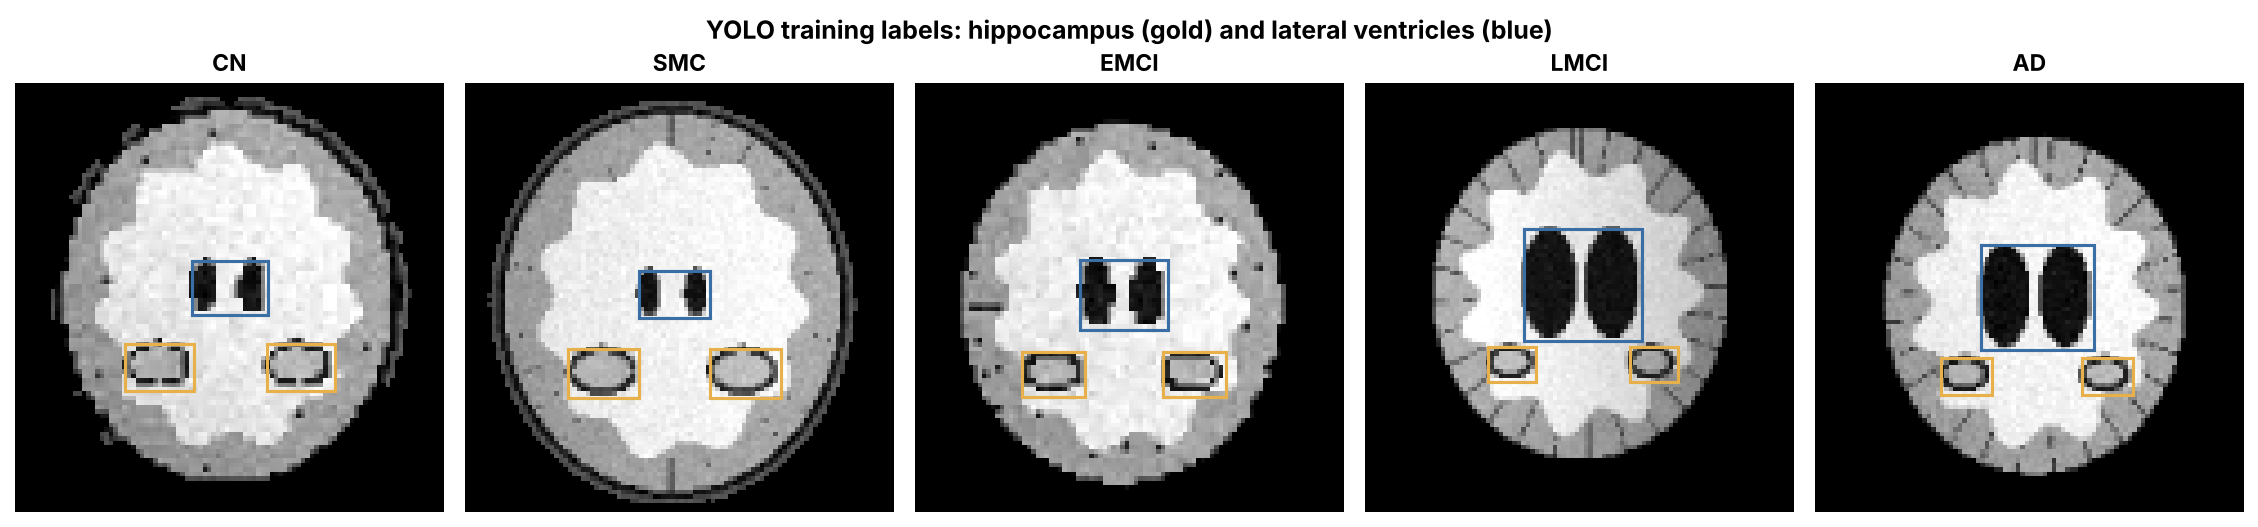

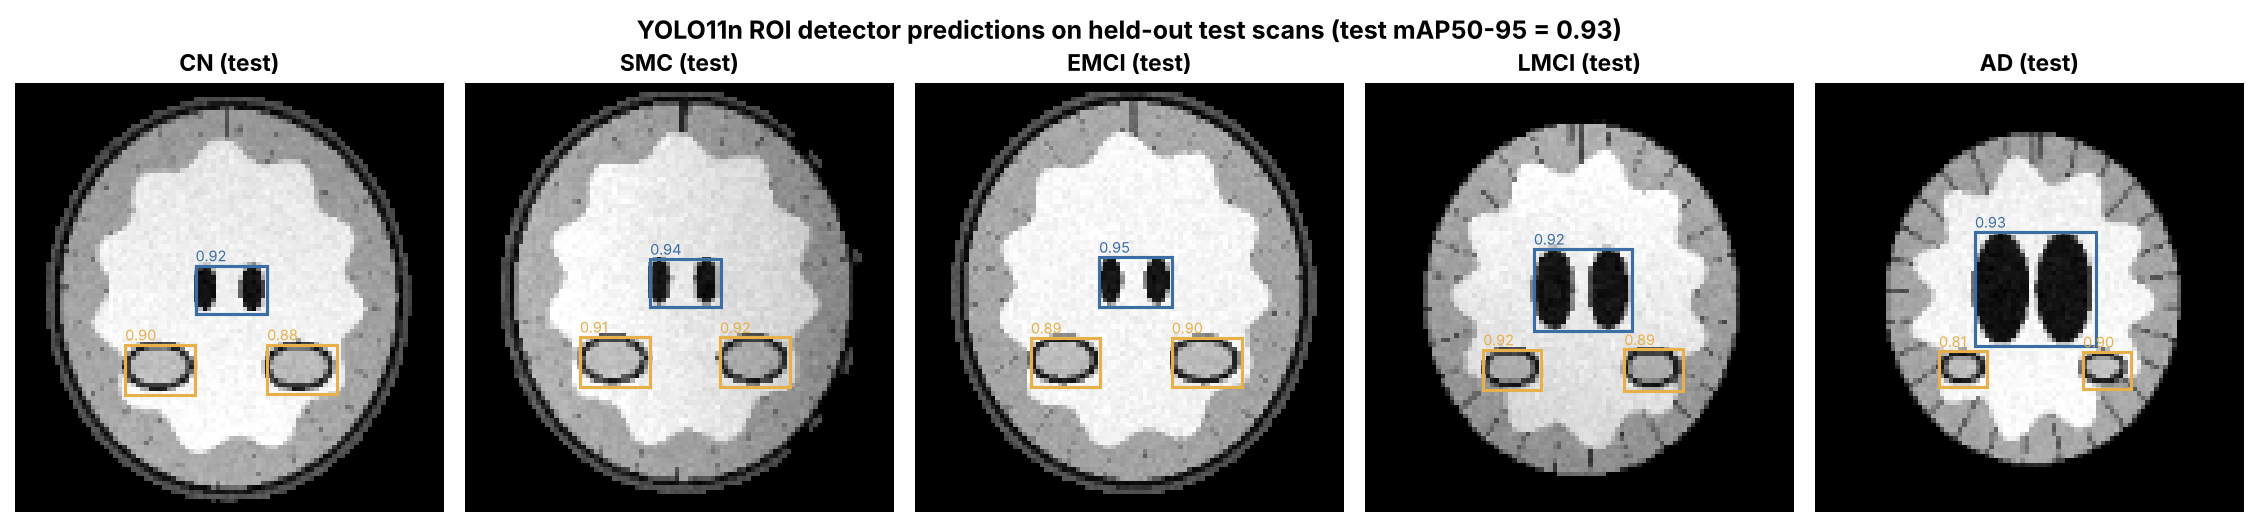

In [2]:
print((ROOT / 'data/yolo/data.yaml').read_text())
print(json.load(open(ROOT / 'reports/metrics/yolo_roi_metrics.json')) if (ROOT / 'reports/metrics/yolo_roi_metrics.json').exists() else 'train with: python -m ad_mm.integrations.yolo_roi train')
show('31_yolo_roi_labels', 1000)
if (FIG / '33_yolo_roi_predictions.png').exists(): show('33_yolo_roi_predictions', 1000)

In [3]:
import importlib.util
for pkg in ['ultralytics', 'fiftyone', 'roboflow', 'darwin']:
    print(f'{pkg:12s}', 'installed' if importlib.util.find_spec(pkg) else 'not installed (optional)')
# FiftyOne:  from ad_mm.integrations.fiftyone_curation import build_dataset; d = build_dataset(predictions_csv=str(ROOT/'reports/metrics/test_predictions.csv'))
# Roboflow:  python -m ad_mm.integrations.roboflow_sync upload --workspace <ws> --project ad-roi
# V7:        python -m ad_mm.integrations.v7_darwin push --team <team> --dataset ad-mri

ultralytics  installed
fiftyone     not installed (optional)
roboflow     not installed (optional)
darwin       not installed (optional)
